# Part H — Building & Evaluating the Regression Model

**Final Project: Philippine Peso Depreciation Early-Warning Model: Predicting the Next-Month PHP/USD Exchange Rate Using Linear Regression and PCA**

This is where every earlier step pays off: the matrices, transformation, and eigenbasis all feed into one final predictive model.

---
**Student name:** Alfajaro, Ghan Vincent | Arile, Charles Jullianne | Asuar, Jhoe Maven | Mondragon, Leneth | Ulitin, Justin   **Date:** November 20, 2026

---


**What to do:** Fit at least two model variants (e.g., using all features vs. using your reduced eigenbasis from Part G). Evaluate both on held-out test data.

In [1]:
# Run this first: recall variables saved from the previous part's notebook.
# (If this is your first notebook in the session, or the store is empty,
#  you'll need to re-run/paste the relevant setup code from the earlier part.)
%store -r X_train X_test y_train y_test Z_train Z_test
%store -r V_k k mu sigma S X_raw y feature_names eigvals eigvecs

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

### Setup check (loads / rebuilds anything missing)

Normally this just loads what Parts A, D, F and G saved with `%store`: the standardized split (342 train / 86 test rows, from Part D) and the PCA scores `Z_train`, `Z_test` (Part G, `k = 2` components covering 99.94% of the variance).

If `%store` is empty (for example after a Colab runtime reset), the cell rebuilds them with the same steps as Parts D, F and G, reading `peso_usd_part_a_dataset.csv` if it exists and otherwise the BSP URL.

In [3]:
try:
    _ = (X_train, X_test, y_train, y_test)
    print("Loaded X_train, X_test, y_train, y_test from %store.")
except NameError:
    print("Store is empty: rebuilding Part D's split...")
    import os
    feature_names = ["CurrentRate", "Trailing3MonthAverage", "YearOverYearChange"]
    if os.path.exists("peso_usd_part_a_dataset.csv"):
        df = pd.read_csv("peso_usd_part_a_dataset.csv", index_col="FeatureMonth")
        X_raw, y = df[feature_names].to_numpy(float), df["NextMonthRate"].to_numpy(float)
    else:
        BSP_URL = "https://www.bsp.gov.ph/statistics/external/pesodollar.xlsx"
        monthly_raw = pd.read_excel(BSP_URL, sheet_name="monthly", header=4, usecols="A:D")
        year = pd.to_numeric(monthly_raw["Period"], errors="coerce").ffill()
        month_name = monthly_raw["Unnamed: 2"].astype(str).str.strip().str.lower()
        rate = pd.to_numeric(monthly_raw["Average"], errors="coerce")
        month_numbers = {"january": 1, "february": 2, "march": 3, "april": 4,
                         "may": 5, "june": 6, "july": 7, "august": 8,
                         "september": 9, "october": 10, "november": 11, "december": 12}
        dates = pd.to_datetime({"year": year, "month": month_name.map(month_numbers), "day": 1}, errors="coerce")
        monthly = pd.DataFrame({"Date": dates, "Rate": rate}).dropna()
        monthly["Date"] = pd.to_datetime(monthly["Date"]).dt.to_period("M").dt.to_timestamp()
        monthly = monthly.sort_values("Date").drop_duplicates("Date", keep="last").set_index("Date")["Rate"].astype(float)
        monthly = monthly.loc["1990-01-01":"2026-09-01"].reindex(pd.date_range("1990-01-01", "2026-09-01", freq="MS"))
        md_ = pd.DataFrame(index=monthly.index)
        md_["CurrentRate"] = monthly
        md_["Trailing3MonthAverage"] = monthly.rolling(window=3).mean()
        md_["YearOverYearChange"] = monthly - monthly.shift(12)
        md_["NextMonthRate"] = monthly.shift(-1)
        md_ = md_.dropna(subset=feature_names + ["NextMonthRate"])
        X_raw, y = md_[feature_names].to_numpy(float), md_["NextMonthRate"].to_numpy(float)

    train_size = int(0.8 * X_raw.shape[0])
    mu = X_raw[:train_size].mean(axis=0)
    sigma = X_raw[:train_size].std(axis=0, ddof=0)
    S = np.diag(1.0 / sigma)
    X_t = (X_raw - mu) @ S
    X_train, X_test = X_t[:train_size], X_t[train_size:]
    y_train, y_test = y[:train_size], y[train_size:]
    print(f"Rebuilt X_train {X_train.shape}, X_test {X_test.shape}.")

try:
    _ = (Z_train, Z_test, V_k)
    print(f"Loaded Z_train {Z_train.shape}, Z_test {Z_test.shape} and V_k {V_k.shape} from %store (Part G).")
except NameError:
    print("Rebuilding Part F/G PCA projection...")
    C = np.cov((X_train - X_train.mean(axis=0)) / X_train.std(axis=0, ddof=1), rowvar=False)
    vals, vecs = np.linalg.eigh(C)
    o = np.argsort(vals)[::-1]
    vals, V = vals[o], vecs[:, o]
    cum = np.cumsum(vals / vals.sum())
    k = int(np.searchsorted(cum, 0.95) + 1)
    V_k = V[:, :k]
    Z_train, Z_test = X_train @ V_k, X_test @ V_k
    print(f"k = {k} components ({cum[k-1]*100:.2f}% of variance).")

print("X_train", X_train.shape, "| Z_train", Z_train.shape, "| y_train", np.shape(y_train))

Loaded X_train, X_test, y_train, y_test from %store.
Loaded Z_train (342, 2), Z_test (86, 2) and V_k (3, 2) from %store (Part G).
X_train (342, 3) | Z_train (342, 2) | y_train (342,)


In [4]:
def fit_normal_equation(X, y):
    """
    Ordinary Least Squares via the Normal Equation:
        b = (X^T X)^-1 X^T y
    with an intercept column of ones prepended.
    Falls back to np.linalg.pinv if X^T X is singular.
    """
    X_aug = np.hstack([np.ones((X.shape[0], 1)), X])
    XtX = X_aug.T @ X_aug
    Xty = X_aug.T @ y
    try:
        beta = np.linalg.inv(XtX) @ Xty
    except np.linalg.LinAlgError:
        print("X^T X is singular -> using the pseudo-inverse instead.")
        beta = np.linalg.pinv(XtX) @ Xty
    return beta

def predict(X, beta):
    X_aug = np.hstack([np.ones((X.shape[0], 1)), X])
    return X_aug @ beta

In [5]:
# Fit Model A (full/transformed feature space) and Model B (PCA eigenbasis)
beta_full = fit_normal_equation(X_train, y_train)
beta_pca = fit_normal_equation(Z_train, y_train)

y_pred_full = predict(X_test, beta_full)
y_pred_pca = predict(Z_test, beta_pca)

print("beta_full (intercept, CurrentRate, Trailing3MonthAverage, YearOverYearChange):")
print(beta_full)
print("\nbeta_pca  (intercept, PC1, PC2, ...):")
print(beta_pca)

# Sanity check against NumPy's built-in least-squares solver
chk = np.linalg.lstsq(np.hstack([np.ones((X_train.shape[0], 1)), X_train]), y_train, rcond=None)[0]
print("\nMax difference vs np.linalg.lstsq (Model A):", np.max(np.abs(beta_full - chk)))

# Conditioning of X^T X for each model (links to Part E/F)
for name, M in [("Model A", X_train), ("Model B", Z_train)]:
    Ma = np.hstack([np.ones((M.shape[0], 1)), M])
    print(f"cond(X^T X) for {name}: {np.linalg.cond(Ma.T @ Ma):.2f}")

beta_full (intercept, CurrentRate, Trailing3MonthAverage, YearOverYearChange):
[42.4979 13.2604 -3.3776  0.0257]

beta_pca  (intercept, PC1, PC2, ...):
[42.4979 -6.9508 -0.6152]

Max difference vs np.linalg.lstsq (Model A): 6.782130412830156e-12
cond(X^T X) for Model A: 1180.24
cond(X^T X) for Model B: 2.05


In [6]:
def r2_score(y_true, y_hat):
    ss_res = np.sum((y_true - y_hat) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    return 1 - ss_res / ss_tot

def rmse(y_true, y_hat):
    return np.sqrt(np.mean((y_true - y_hat) ** 2))

def mae(y_true, y_hat):
    return np.mean(np.abs(y_true - y_hat))

results = pd.DataFrame({
    "Model A (all 3 features)": [r2_score(y_test, y_pred_full), rmse(y_test, y_pred_full), mae(y_test, y_pred_full)],
    f"Model B (PCA, k={Z_train.shape[1]})": [r2_score(y_test, y_pred_pca), rmse(y_test, y_pred_pca), mae(y_test, y_pred_pca)],
}, index=["R^2", "RMSE (PHP per USD)", "MAE (PHP per USD)"])
print("TEST-SET RESULTS")
display(results.round(4))

# Training-set R^2 too, to check for overfitting
print("Train R^2  Model A:", round(r2_score(y_train, predict(X_train, beta_full)), 4),
      "| Model B:", round(r2_score(y_train, predict(Z_train, beta_pca)), 4))

# Baseline: "next month = this month" (naive forecast) using the CurrentRate column, un-standardized
try:
    cur = X_raw[:, 0]
    ts = len(y_train)
    naive = cur[ts:]
    print("Naive baseline (next = current) test R^2:", round(r2_score(y_test, naive), 4),
          "| RMSE:", round(rmse(y_test, naive), 4))
except Exception as e:
    print("Baseline skipped:", e)

TEST-SET RESULTS


,Model A (all 3 features),"Model B (PCA, k=2)"
R^2,0.9631,0.9527
RMSE (PHP per USD),0.7673,0.8681
MAE (PHP per USD),0.5908,0.6690


Train R^2  Model A: 0.9946 | Model B: 0.9922
Naive baseline (next = current) test R^2: 0.9625 | RMSE: 0.773


### Visualizations (required by the project guidelines)
Three plots: (1) a scree plot, (2) a PCA projection, and (3) predicted vs. actual for both models.

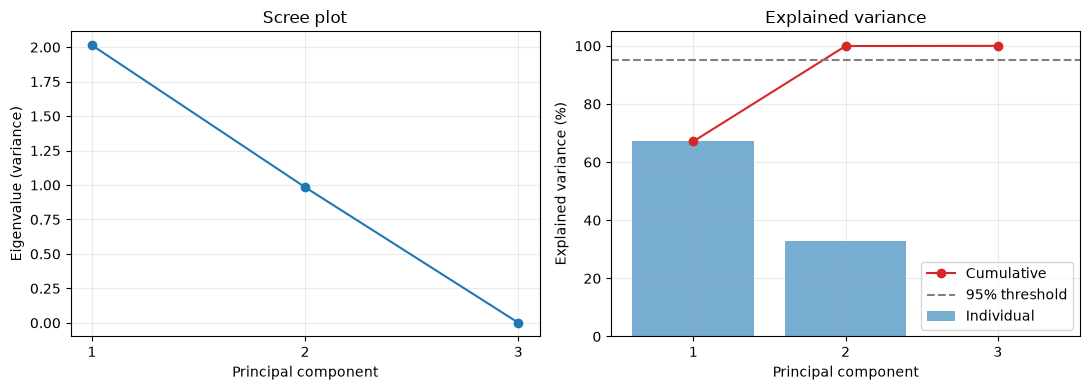

In [7]:
# Variables from Part G (loaded from %store, or rebuilt from X_train if they are missing)
if not all(n in globals() for n in ["eigvals_sorted", "V", "explained_var_ratio", "cum_var"]):
    if "eigvals" in globals() and "eigvecs" in globals():
        _vals, _vecs = np.asarray(eigvals, dtype=float).ravel(), np.asarray(eigvecs, dtype=float)
    else:
        _vals, _vecs = np.linalg.eigh(np.cov(X_train, rowvar=False))
    _o = np.argsort(_vals)[::-1]
    eigvals_sorted = np.clip(_vals[_o], 0, None)
    V = _vecs[:, _o]
    explained_var_ratio = eigvals_sorted / eigvals_sorted.sum()
    cum_var = np.cumsum(explained_var_ratio)

# Scree plot and cumulative explained variance (reused in the Part H report)
pcs = np.arange(1, len(eigvals_sorted) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(pcs, eigvals_sorted, "o-")
axes[0].set_xticks(pcs)
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Eigenvalue (variance)")
axes[0].set_title("Scree plot")
axes[0].grid(alpha=0.25)

axes[1].bar(pcs, explained_var_ratio * 100, alpha=0.6, label="Individual")
axes[1].plot(pcs, cum_var * 100, "o-", color="tab:red", label="Cumulative")
axes[1].axhline(95, color="gray", linestyle="--", label="95% threshold")
axes[1].set_xticks(pcs)
axes[1].set_xlabel("Principal component")
axes[1].set_ylabel("Explained variance (%)")
axes[1].set_title("Explained variance")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

**Scree plot: what it shows.** The eigenvalues drop sharply after PC1 and PC2 (2.0141 and 0.9841) and then fall almost to zero at PC3 (0.0017). The "elbow" is at PC2. In the right panel, PC1 explains about 67.1% of the variance and PC1 + PC2 together reach about 99.94%, well past the 95% threshold, so k = 2 components are enough. PC3 holds only about 0.06% of the variance, which is why it was dropped for Model B. This is the same near-linear dependence (correlation of about 0.998 between CurrentRate and Trailing3MonthAverage) found in Parts E and F.

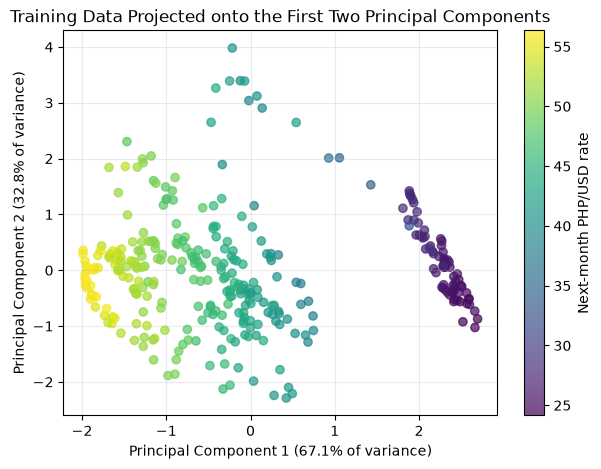

In [8]:
Z_plot = X_train @ V[:, :2]

plt.figure(figsize=(7, 5))
sc = plt.scatter(Z_plot[:, 0], Z_plot[:, 1], c=y_train, cmap="viridis", alpha=0.7)
plt.xlabel(f"Principal Component 1 ({explained_var_ratio[0]*100:.1f}% of variance)")
plt.ylabel(f"Principal Component 2 ({explained_var_ratio[1]*100:.1f}% of variance)")
plt.title("Training Data Projected onto the First Two Principal Components")
plt.colorbar(sc, label="Next-month PHP/USD rate")
plt.grid(alpha=0.25)
plt.show()

**PCA projection: what it shows.** Each point is one training month, reduced from 3 standardized features to 2 principal-component scores (Z = X V[:, :2], the same projection as Part G). The color is the next-month PHP/USD rate. The color changes steadily along the PC1 axis, which loads almost equally on CurrentRate and Trailing3MonthAverage, so PC1 is basically the overall *level* of the peso-dollar rate and is the main driver of the target. PC2 is almost entirely YearOverYearChange (the trend), and it spreads the months out vertically. The sign of an eigenvector is arbitrary, so the direction of the PC1 axis could be flipped without changing the meaning.

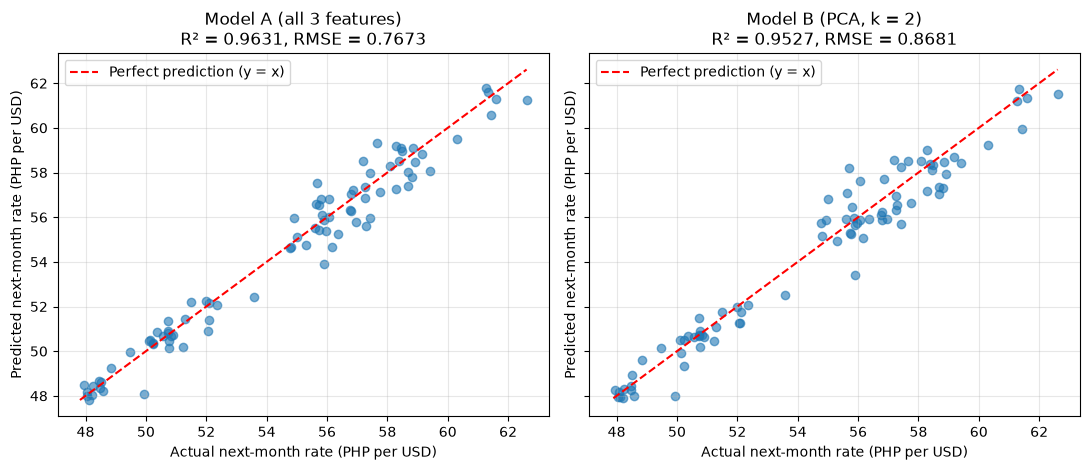

In [9]:
# 3) PREDICTED vs. ACTUAL for both models
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharex=True, sharey=True)
for ax, y_hat, title in zip(axes, [y_pred_full, y_pred_pca],
                            [f"Model A (all 3 features)\nR² = {r2_score(y_test, y_pred_full):.4f}, RMSE = {rmse(y_test, y_pred_full):.4f}",
                             f"Model B (PCA, k = {Z_train.shape[1]})\nR² = {r2_score(y_test, y_pred_pca):.4f}, RMSE = {rmse(y_test, y_pred_pca):.4f}"]):
    ax.scatter(y_test, y_hat, alpha=0.6)
    lims = [min(y_test.min(), y_hat.min()), max(y_test.max(), y_hat.max())]
    ax.plot(lims, lims, "r--", label="Perfect prediction (y = x)")
    ax.set_xlabel("Actual next-month rate (PHP per USD)")
    ax.set_ylabel("Predicted next-month rate (PHP per USD)")
    ax.set_title(title); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Predicted vs. actual: what it shows.** Points close to the red dashed line (y = x) are accurate predictions. Both models follow the line closely, which matches their high test R² (0.9631 and 0.9527). Model A's points sit slightly closer to the line than Model B's, consistent with its lower RMSE (0.7673 vs 0.8681 pesos). The scatter around the line is the prediction error, and a systematic drift away from the line at high or low rates would indicate bias.

### Depreciation / appreciation signal (from our project proposal)
The model predicts next month's PHP/USD rate. The **signal** for each test month is

**signal = predicted next-month rate − current rate**

A **positive** signal means the model expects more pesos per US dollar next month, which is a **possible depreciation of the peso** (the peso gets weaker). A **negative** signal means a possible **appreciation**. To check whether the signal is useful, we compare its sign with the sign of the *actual* change (actual next-month rate − current rate) and report the **directional accuracy**, the share of months where the model got the direction right.

Test months: 86 (months with a non-zero actual change: 86)
Actual depreciation months: 51.2% | actual appreciation months: 48.8%
Accuracy of always guessing the majority direction: 51.2%



,Directional accuracy (%),Predicted depreciation months,Predicted appreciation months,Depreciation precision (%),Depreciation recall (%)
Model,,,,,
Model A (all 3 features),53.49,46,40,54.35,56.82
"Model B (PCA, k=2)",50.00,31,55,51.61,36.36



Last 12 test months (signal = predicted rate - current rate; > 0 means possible depreciation):


,CurrentRate,ActualNextRate,ActualChange,Signal_A,Call_A,Signal_B,Call_B
FeatureMonth,,,,,,,
2025-09-01,57.2501,58.2984,1.0483,0.0138,Depreciation,-0.0886,Appreciation
2025-10-01,58.2984,58.9136,0.6151,0.1875,Depreciation,-0.3739,Appreciation
2025-11-01,58.9136,58.8488,-0.0647,0.1995,Depreciation,-0.4624,Appreciation
2025-12-01,58.8488,59.1622,0.3134,-0.0019,Appreciation,-0.1530,Appreciation
2026-01-01,59.1622,58.2803,-0.8819,0.0074,Depreciation,-0.1430,Appreciation
2026-02-01,58.2803,59.4069,1.1266,-0.2192,Appreciation,0.1572,Depreciation
2026-03-01,59.4069,60.2913,0.8844,0.1056,Depreciation,-0.1965,Appreciation
2026-04-01,60.2913,61.4410,1.1497,0.2827,Depreciation,-0.3567,Appreciation
2026-05-01,61.4410,61.2513,-0.1897,0.3244,Depreciation,-0.2520,Appreciation


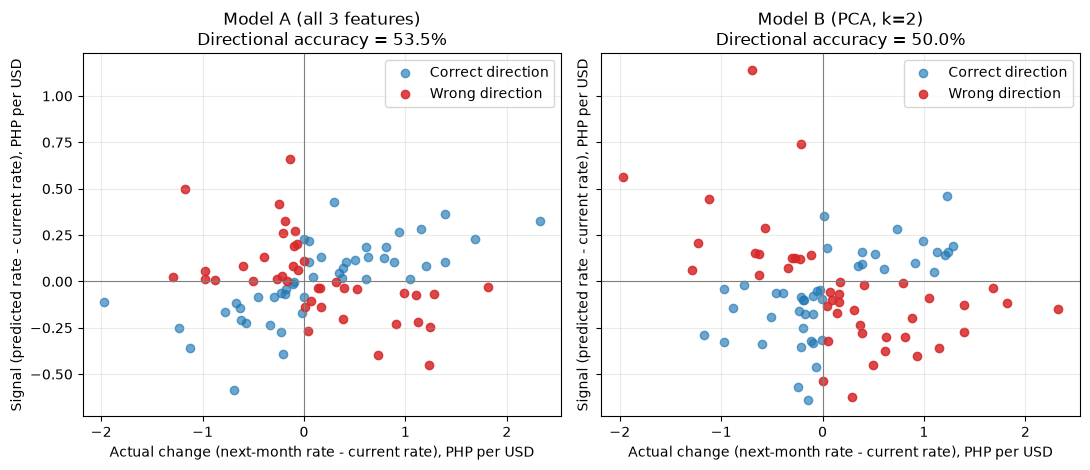

Model A (all 3 features): directional accuracy = 53.5% (vs. 51.2% for always guessing the majority direction); it flagged 46 months as possible depreciation, 54.4% of which were real depreciations.
Model B (PCA, k=2): directional accuracy = 50.0% (vs. 51.2% for always guessing the majority direction); it flagged 31 months as possible depreciation, 51.6% of which were real depreciations.


In [10]:
# Depreciation / appreciation signal = predicted next-month rate - current rate
ts = len(y_train)

# Raw (un-standardized) CurrentRate of each test month
if "X_raw" in globals():
    cur_test = np.asarray(X_raw, dtype=float)[ts:, 0]
elif "mu" in globals() and "sigma" in globals():
    cur_test = X_test[:, 0] * np.asarray(sigma)[0] + np.asarray(mu)[0]      # undo Part D's standardization
else:
    raise RuntimeError("Need X_raw (Part A) or mu/sigma (Part D) to recover the raw CurrentRate.")
assert len(cur_test) == len(y_test)

try:   # month labels, if the Part A csv is available
    months = pd.read_csv("peso_usd_part_a_dataset.csv", index_col="FeatureMonth").index[ts:]
    assert len(months) == len(y_test)
except Exception:
    months = pd.RangeIndex(len(y_test), name="test month #")

actual_change = y_test - cur_test                 # > 0 : peso actually depreciated
models = {"Model A (all 3 features)": y_pred_full, f"Model B (PCA, k={Z_train.shape[1]})": y_pred_pca}

nz = actual_change != 0                           # months with no change have no direction
summary, signals = [], pd.DataFrame({"CurrentRate": cur_test, "ActualNextRate": y_test,
                                     "ActualChange": actual_change}, index=months)
for name, y_hat in models.items():
    sig = y_hat - cur_test                        # the signal
    pred_dep, act_dep = sig[nz] > 0, actual_change[nz] > 0
    tp = np.sum(pred_dep & act_dep);  fp = np.sum(pred_dep & ~act_dep)
    fn = np.sum(~pred_dep & act_dep); tn = np.sum(~pred_dep & ~act_dep)
    summary.append({"Model": name,
                    "Directional accuracy (%)": 100 * (tp + tn) / nz.sum(),
                    "Predicted depreciation months": int(tp + fp),
                    "Predicted appreciation months": int(fn + tn),
                    "Depreciation precision (%)": 100 * tp / max(tp + fp, 1),
                    "Depreciation recall (%)": 100 * tp / max(tp + fn, 1)})
    tag = "A" if name.startswith("Model A") else "B"
    signals[f"Signal_{tag}"] = sig
    signals[f"Call_{tag}"] = np.where(sig > 0, "Depreciation", "Appreciation")
    models[name] = (y_hat, sig)

summary = pd.DataFrame(summary).set_index("Model").round(2)
base = 100 * np.mean(actual_change[nz] > 0)
print(f"Test months: {len(y_test)} (months with a non-zero actual change: {nz.sum()})")
print(f"Actual depreciation months: {base:.1f}% | actual appreciation months: {100 - base:.1f}%")
print(f"Accuracy of always guessing the majority direction: {max(base, 100 - base):.1f}%\n")
display(summary)
print("\nLast 12 test months (signal = predicted rate - current rate; > 0 means possible depreciation):")
display(signals.tail(12).round(4))

# Plot: signal vs. actual change (points in the top-right / bottom-left quadrants are correct calls)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharex=True, sharey=True)
for ax, (name, (y_hat, sig)) in zip(axes, models.items()):
    ok = np.sign(sig) == np.sign(actual_change)
    ax.scatter(actual_change[ok], sig[ok], alpha=0.65, label="Correct direction")
    ax.scatter(actual_change[~ok], sig[~ok], alpha=0.85, color="tab:red", label="Wrong direction")
    ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
    ax.set_xlabel("Actual change (next-month rate - current rate), PHP per USD")
    ax.set_ylabel("Signal (predicted rate - current rate), PHP per USD")
    ax.set_title(f"{name}\nDirectional accuracy = {summary.loc[name, 'Directional accuracy (%)']:.1f}%")
    ax.legend(); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

for name in summary.index:
    r = summary.loc[name]
    print(f"{name}: directional accuracy = {r['Directional accuracy (%)']:.1f}% "
          f"(vs. {max(base, 100 - base):.1f}% for always guessing the majority direction); "
          f"it flagged {int(r['Predicted depreciation months'])} months as possible depreciation, "
          f"{r['Depreciation precision (%)']:.1f}% of which were real depreciations.")

### Answer these in your report

**Q29.** Write the closed-form equation you used to fit your regression coefficients. What single linear algebra operation is at the core of it?

> *Your answer:* _(We used the Normal Equation: **β = (XᵀX)⁻¹ Xᵀ y**, where X is the training feature matrix with a column of ones added in front for the intercept, y is the vector of next-month exchange rates, and β holds the intercept and one coefficient per feature. The single operation at the core is the **matrix inverse** of XᵀX (equivalently, solving the linear system XᵀX β = Xᵀy). Geometrically, it finds the orthogonal projection of y onto the column space of X. If XᵀX is singular, we use the pseudo-inverse instead.)_

**Q30.** Report at least two evaluation metrics (e.g., R², RMSE, MAE) on the test set for each model variant.

> *Your answer:* On the held-out test set (the last 86 months, chronologically after the training data), the two models scored as follows:
>
> | Metric | Model A (all 3 standardized features) | Model B (PCA, k = 2) |
> |---|---|---|
> | R² | 0.9631 | 0.9527 |
> | RMSE (PHP per USD) | 0.7673 | 0.8681 |
> | MAE (PHP per USD) | 0.5908 | 0.6690 |
>
> Model A achieved R² = 0.9631, RMSE = 0.7673 pesos and MAE = 0.5908 pesos. Model B achieved R² = 0.9527, RMSE = 0.8681 pesos and MAE = 0.6690 pesos. On the training set the R² values were 0.9946 for Model A and 0.9922 for Model B. For reference, the naive forecast "next month = this month" scored R² = 0.9625 and RMSE = 0.7730 on the same test set.

**Q31.** Which model variant performed better? Connect that result back to one specific earlier finding (e.g., rank, eigenvalues, condition number).

> *Your answer:* **Model A (all 3 features) performed better** on every metric. Its test RMSE was 0.7673 versus 0.8681 for Model B (Model B's RMSE is about 13% *higher* than Model A's), its MAE was 0.5908 versus 0.6690 (also about 13% higher for Model B), and its R² was 0.9631 versus 0.9527.
>
> This connects to our Part F and Part G eigenvalue results. The covariance eigenvalues were 2.0141, 0.9841 and 0.0017, and CurrentRate and Trailing3MonthAverage are almost perfectly correlated (about 0.998). That made the third principal component, PC3 = (−0.7079, 0.7060, 0.0201), essentially *Trailing3MonthAverage minus CurrentRate*, with only 0.06% of the total variance, so Model B discarded it. Dropping it made the problem much better conditioned (the eigenvalue ratio fell from about 1,180 to about 2.05), but it did not improve accuracy. PCA is unsupervised: it ranks directions by how much the features vary and never looks at the target. PC3 is small in variance but it is a short-term momentum signal (how far the latest month moved from the previous two), and that information helps predict next month's rate. Removing it cost accuracy.
>
> Two further observations support this. First, Model B's features are linear combinations of Model A's (Z = X V_k), so Model A can never fit the training data worse, and its training R² was indeed slightly higher (0.9946 vs 0.9922). Second, the gap grew on the test set (R² difference of 0.0104 versus 0.0024 in training), which suggests the discarded direction mattered more in the 2019–2026 test period than in the training period.
>
> Finally, an honest caveat: Model A only slightly beats the naive baseline "next month = this month" (RMSE 0.7673 vs 0.7730, R² 0.9631 vs 0.9625), and Model B does not beat it. Most of the predictive power therefore comes from the current rate level itself, and the extra features add only a small improvement. The near-collinearity in the features did not hurt Model A's accuracy, because the Normal Equation can still be solved reliably at this level of conditioning. The benefit of PCA here is a simpler, more stable model, not a more accurate one.

**Q32.** Walk through, step-by-step, every matrix operation your pipeline would perform to turn one brand-new sample's raw features into a final prediction.

> *Your answer:* For one new month, let **x** = [CurrentRate, Trailing3MonthAverage, YearOverYearChange] be the raw 1×3 feature row (for example, this month's rate, the average of this month and the previous two, and this month's rate minus the rate 12 months ago). Every constant below comes from the **training set only**, so there is no leakage.
>
> 1. **Center (Part D):** subtract the training mean vector, x̃ = x − μ, with μ = [42.4302, 42.3602, 0.9993].
> 2. **Scale (Part D):** multiply by the diagonal matrix S = diag(1/σ₁, 1/σ₂, 1/σ₃) = diag(0.1006, 0.1006, 0.2588), giving the standardized row x_std = x̃ S (1×3 times 3×3).
> 3. **Project (Parts F and G, Model B only):** multiply by V_k, the 3×2 matrix of the first two eigenvectors of the covariance matrix, giving z = x_std V_k (1×2). These are the scores on PC1 and PC2.
> 4. **Add the intercept:** prepend a 1 to get [1, z] (Model A uses [1, x_std] and skips step 3).
> 5. **Predict:** take the dot product with the coefficient vector found by the Normal Equation, ŷ = [1, z] β, which is a 1×3 times 3×1 product for Model B (1×4 times 4×1 for Model A).
>
> All together: **ŷ = [1, ((x − μ) S) V_k] β_pca**. The result ŷ is already in pesos per US dollar, because only the features were standardized, not the target y, so no inverse transformation is needed on the output. The cell below runs this by hand on a real test-period month and checks that it matches `predict()`.

In [11]:
# Demo for Q32: run ONE sample through the whole pipeline by hand and compare with predict()
ts = len(y_train)
if "X_raw" not in globals():
    # No raw data in memory: undo Part D's standardization on the first test row
    x_new = X_test[0] @ np.diag(sigma) + mu
    y_actual = y_test[0]
else:
    x_new = X_raw[ts]                          # first raw sample of the test period
    y_actual = y_test[0]
mu_ = mu if "mu" in globals() else X_raw[:ts].mean(axis=0)
sigma_ = sigma if "sigma" in globals() else X_raw[:ts].std(axis=0, ddof=0)
S_ = np.diag(1.0 / sigma_)

step1 = x_new - mu_                            # 1. center
step2 = step1 @ S_                             # 2. scale  (= standardized row)
step3 = step2 @ V_k                            # 3. project onto the k eigenvectors
y_hat_B = np.hstack([1.0, step3]) @ beta_pca   # 4+5. intercept + dot product with beta
y_hat_A = np.hstack([1.0, step2]) @ beta_full

print("Raw x:          ", x_new)
print("Centered:       ", step1)
print("Standardized:   ", step2)
print("PCA scores z:   ", step3)
print(f"Model A prediction: {y_hat_A:.4f} | Model B prediction: {y_hat_B:.4f} | Actual: {y_actual:.4f}")
print("Matches predict()?", np.isclose(y_hat_A, y_pred_full[0]), np.isclose(y_hat_B, y_pred_pca[0]))

Raw x:           [51.1429 51.7359 -2.29  ]
Centered:        [ 8.7126  9.3758 -3.2893]
Standardized:    [ 0.8763  0.9429 -0.8513]
PCA scores z:    [-1.1692 -1.0069]
Model A prediction: 50.9120 | Model B prediction: 51.2444 | Actual: 52.0547
Matches predict()? True True


### Save your work for the next notebook

In [12]:
%store beta_full
%store beta_pca
print("Saved beta_full, beta_pca for Part I.")

Stored 'beta_full' (ndarray)
Stored 'beta_pca' (ndarray)
Saved beta_full, beta_pca for Part I.


In [13]:
"""Extra diagnostics quoted in the manuscript but not printed by Parts A-H.
Run in the folder that contains peso_usd_part_a_dataset.csv (written by Part A):  python manuscript_extra_checks.py
It repeats the Part D/F/G/H pipeline (chronological 80/20 split, train-only standardization, PCA k = 2, OLS) and prints:
  Sec 3.2  singular values / condition number of the RAW 342 x 3 training matrix
  Sec 3.4  variance inflation factors (diagonal of the inverse correlation matrix)
  Sec 3.6  Frobenius norm of C - V Lambda V^T
  Sec 4.6  test error by terciles of the actual rate, direction accuracy, extrapolation share
  Sec 5.3  naive-baseline MAE and the CurrentRate-only / fewer-features check
"""
import numpy as np, pandas as pd

df = pd.read_csv("peso_usd_part_a_dataset.csv", index_col="FeatureMonth")
F = ["CurrentRate", "Trailing3MonthAverage", "YearOverYearChange"]
X, y = df[F].to_numpy(float), df["NextMonthRate"].to_numpy(float)
ts = int(0.8 * len(X))
Xtr, Xte, ytr, yte = X[:ts], X[ts:], y[:ts], y[ts:]
mu, sd = Xtr.mean(0), Xtr.std(0)
Ztr, Zte = (Xtr - mu) / sd, (Xte - mu) / sd

sv = np.linalg.svd(Xtr, compute_uv=False)
print("3.2 raw X_train rank:", np.linalg.matrix_rank(Xtr), "| singular values:", sv.round(4), "| cond:", round(sv[0] / sv[-1], 2))

C = np.corrcoef(Ztr, rowvar=False)
w, V = np.linalg.eigh(C); o = np.argsort(w)[::-1]; w, V = w[o], V[:, o]
print("3.4 VIF:", np.diag(np.linalg.inv(C)).round(2))
print("3.6 ||C - V Lambda V^T||_F =", np.linalg.norm(C - V @ np.diag(w) @ V.T, "fro"))

Vk = V[:, :2]; Ptr, Pte = Ztr @ Vk, Zte @ Vk
def fit(A, b):  return np.linalg.lstsq(np.c_[np.ones(len(A)), A], b, rcond=None)[0]
def pred(A, b): return np.c_[np.ones(len(A)), A] @ b
def met(p, t):
    e = t - p
    return dict(rmse=np.sqrt((e**2).mean()), r2=1 - (e**2).sum() / ((t - t.mean())**2).sum(), mae=np.abs(e).mean(), bias=e.mean())
bA, bB = fit(Ztr, ytr), fit(Ptr, ytr)
pA, pB, naive = pred(Zte, bA), pred(Pte, bB), Xte[:, 0]
for n, p in (("Model A", pA), ("Model B", pB), ("naive", naive)):
    print("5.3", n, {k: round(float(v), 4) for k, v in met(p, yte).items()})

q = np.quantile(yte, [1/3, 2/3]); band = np.digitize(yte, q)
print("4.6 error by tercile of the actual rate (RMSE A, B, naive, mean error A):")
for b in range(3):
    m = band == b
    print(f"   {yte[m].min():.2f}-{yte[m].max():.2f} n={m.sum()}",
          round(float(np.sqrt(((yte - pA)[m]**2).mean())), 4), round(float(np.sqrt(((yte - pB)[m]**2).mean())), 4),
          round(float(np.sqrt(((yte - naive)[m]**2).mean())), 4), round(float((yte - pA)[m].mean()), 4))
act = np.sign(yte - Xte[:, 0])
print("4.6 direction accuracy A, B:", np.mean(np.sign(pA - Xte[:, 0]) == act).round(3), np.mean(np.sign(pB - Xte[:, 0]) == act).round(3),
      "| share of months the rate rose:", np.mean(act > 0).round(3))
print("1.4 test months above the training maximum rate:", int((Xte[:, 0] > Xtr[:, 0].max()).sum()), "of", len(Xte),
      "| train max", Xtr[:, 0].max().round(2), "| test max", Xte[:, 0].max().round(2))
print("5.3 fewer features (test R2, RMSE):")
for name, cols in (("CurrentRate only", [0]), ("CurrentRate + Trailing3MonthAverage", [0, 1]), ("all three", [0, 1, 2])):
    m = met(pred(Zte[:, cols], fit(Ztr[:, cols], ytr)), yte)
    print("   ", name, round(float(m["r2"]), 4), round(float(m["rmse"]), 4))

3.2 raw X_train rank: 3 | singular values: [1138.999    71.2782    7.5946] | cond: 149.97
3.4 VIF: [293.88 292.36   1.25]
3.6 ||C - V Lambda V^T||_F = 1.1340793697364378e-15
5.3 Model A {'rmse': 0.7673, 'r2': 0.9631, 'mae': 0.5908, 'bias': 0.1228}
5.3 Model B {'rmse': 0.8681, 'r2': 0.9527, 'mae': 0.669, 'bias': 0.186}
5.3 naive {'rmse': 0.773, 'r2': 0.9625, 'mae': 0.5822, 'bias': 0.1334}
4.6 error by tercile of the actual rate (RMSE A, B, naive, mean error A):
   47.96-51.50 n=29 0.5111 0.5419 0.513 -0.0044
   51.98-56.79 n=28 0.8388 1.0213 0.8642 0.1208
   56.85-62.61 n=29 0.8975 0.9665 0.8874 0.2519
4.6 direction accuracy A, B: 0.535 0.5 | share of months the rate rose: 0.512
1.4 test months above the training maximum rate: 32 of 86 | train max 56.34 | test max 61.6
5.3 fewer features (test R2, RMSE):
    CurrentRate only 0.9626 0.772
    CurrentRate + Trailing3MonthAverage 0.9631 0.767
    all three 0.9631 0.7673
